<a href="https://colab.research.google.com/github/NermineBouzidi/cifar10-mlp-vs-cnn/blob/main/cifar10_mlp_vs_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3681s 22us/step
(50000, 32, 32, 3) (10000, 32, 32, 3)


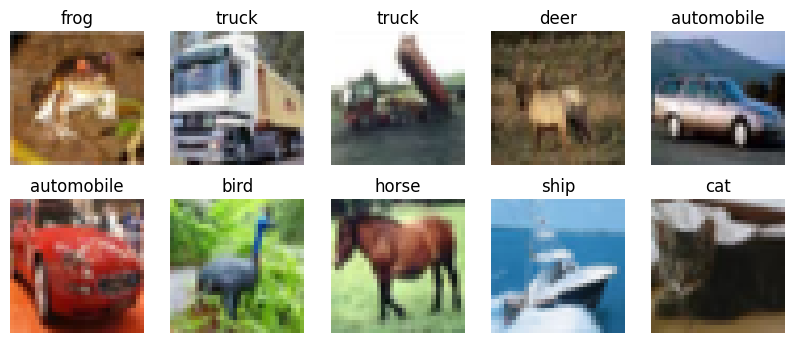

In [1]:
import numpy as np, time
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
class_names = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

x_train = x_train.astype('float32') / 255.0
x_test  = x_test.astype('float32') / 255.0
y_train, y_test = y_train.flatten(), y_test.flatten()

print(x_train.shape, x_test.shape)

# Quick look at the data
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i]); plt.title(class_names[y_train[i]]); plt.axis('off')
plt.show()

In [2]:
mlp = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dense(256, activation='relu'),
    layers.Dense(10, activation='softmax')
])
mlp.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])
mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

In [3]:
start = time.time()
history_mlp = mlp.fit(x_train, y_train, epochs=20, batch_size=128,
                      validation_split=0.1, verbose=2)
mlp_time = time.time() - start
print(f"Training time: {mlp_time:.1f}s")

Epoch 1/20
352/352 - 6s - 18ms/step - accuracy: 0.3180 - loss: 1.9143 - val_accuracy: 0.3762 - val_loss: 1.7437
Epoch 2/20
352/352 - 1s - 4ms/step - accuracy: 0.3908 - loss: 1.6960 - val_accuracy: 0.3942 - val_loss: 1.6892
Epoch 3/20
352/352 - 1s - 4ms/step - accuracy: 0.4277 - loss: 1.6093 - val_accuracy: 0.4118 - val_loss: 1.6541
Epoch 4/20
352/352 - 1s - 4ms/step - accuracy: 0.4505 - loss: 1.5465 - val_accuracy: 0.4546 - val_loss: 1.5343
Epoch 5/20
352/352 - 1s - 4ms/step - accuracy: 0.4666 - loss: 1.4986 - val_accuracy: 0.4616 - val_loss: 1.5265
Epoch 6/20
352/352 - 1s - 4ms/step - accuracy: 0.4818 - loss: 1.4621 - val_accuracy: 0.4768 - val_loss: 1.4880
Epoch 7/20
352/352 - 1s - 4ms/step - accuracy: 0.4881 - loss: 1.4344 - val_accuracy: 0.4656 - val_loss: 1.4934
Epoch 8/20
352/352 - 1s - 4ms/step - accuracy: 0.4991 - loss: 1.4093 - val_accuracy: 0.4824 - val_loss: 1.4569
Epoch 9/20
352/352 - 1s - 4ms/step - accuracy: 0.5096 - loss: 1.3766 - val_accuracy: 0.4706 - val_loss: 1.5126


MLP test accuracy: 0.5148


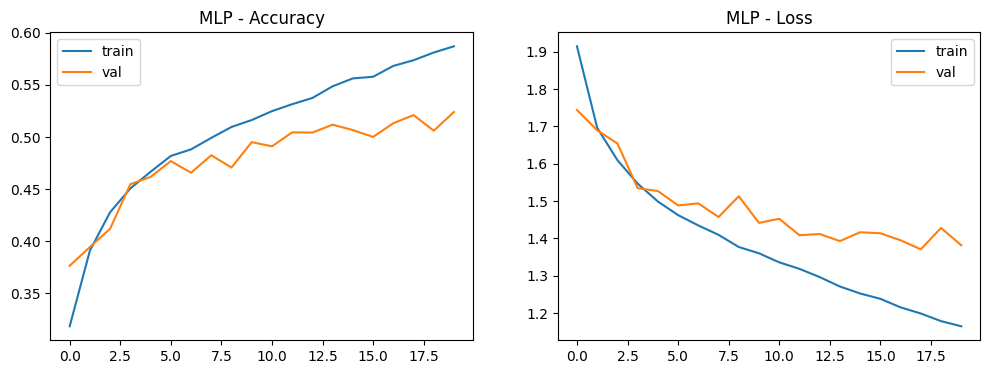

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


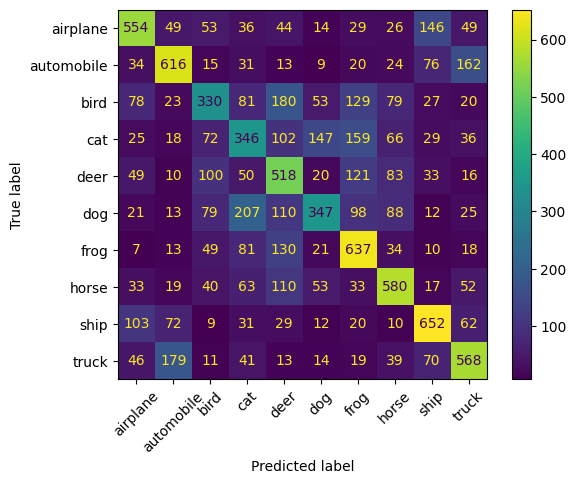

In [4]:
test_loss, test_acc = mlp.evaluate(x_test, y_test, verbose=0)
print(f"MLP test accuracy: {test_acc:.4f}")

def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.history['accuracy'], label='train'); ax[0].plot(h.history['val_accuracy'], label='val')
    ax[0].set_title(f'{title} - Accuracy'); ax[0].legend()
    ax[1].plot(h.history['loss'], label='train'); ax[1].plot(h.history['val_loss'], label='val')
    ax[1].set_title(f'{title} - Loss'); ax[1].legend()
    plt.show()

plot_history(history_mlp, 'MLP')

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
y_pred = np.argmax(mlp.predict(x_test), axis=1)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=class_names).plot(xticks_rotation=45)
plt.show()

In [5]:
cnn = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])
cnn.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
start = time.time()
history_cnn = cnn.fit(x_train, y_train, epochs=20, batch_size=128,
                      validation_split=0.1, verbose=2)
cnn_time = time.time() - start
print(f"Training time: {cnn_time:.1f}s")

Epoch 1/20
352/352 - 15s - 43ms/step - accuracy: 0.4359 - loss: 1.5499 - val_accuracy: 0.5420 - val_loss: 1.2769
Epoch 2/20
352/352 - 3s - 8ms/step - accuracy: 0.5946 - loss: 1.1490 - val_accuracy: 0.6448 - val_loss: 1.0094
Epoch 3/20
352/352 - 3s - 7ms/step - accuracy: 0.6603 - loss: 0.9749 - val_accuracy: 0.6784 - val_loss: 0.9228
Epoch 4/20
352/352 - 3s - 7ms/step - accuracy: 0.6994 - loss: 0.8641 - val_accuracy: 0.7082 - val_loss: 0.8357
Epoch 5/20
352/352 - 3s - 7ms/step - accuracy: 0.7291 - loss: 0.7810 - val_accuracy: 0.7118 - val_loss: 0.8373
Epoch 6/20
352/352 - 3s - 7ms/step - accuracy: 0.7570 - loss: 0.7052 - val_accuracy: 0.7404 - val_loss: 0.7758
Epoch 7/20
352/352 - 3s - 7ms/step - accuracy: 0.7758 - loss: 0.6467 - val_accuracy: 0.7478 - val_loss: 0.7352
Epoch 8/20
352/352 - 3s - 7ms/step - accuracy: 0.7965 - loss: 0.5856 - val_accuracy: 0.7518 - val_loss: 0.7382
Epoch 9/20
352/352 - 3s - 7ms/step - accuracy: 0.8184 - loss: 0.5265 - val_accuracy: 0.7350 - val_loss: 0.7943

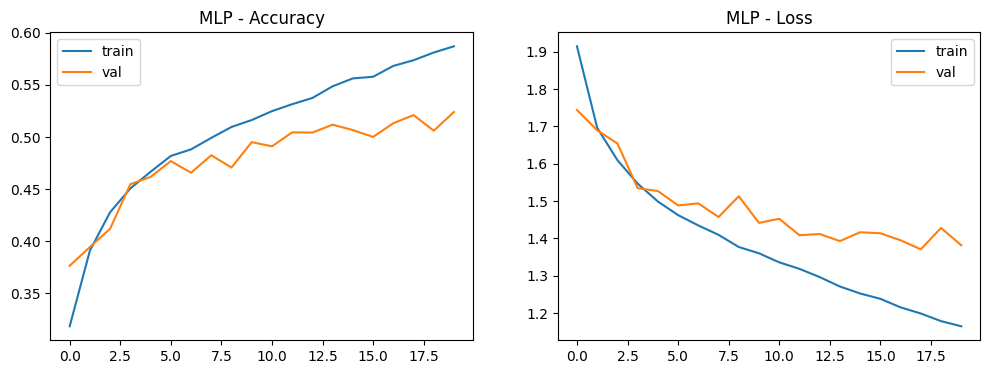

In [7]:
def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.history['accuracy'], label='train'); ax[0].plot(h.history['val_accuracy'], label='val')
    ax[0].set_title(f'{title} - Accuracy'); ax[0].legend()
    ax[1].plot(h.history['loss'], label='train'); ax[1].plot(h.history['val_loss'], label='val')
    ax[1].set_title(f'{title} - Loss'); ax[1].legend()
    plt.savefig(f'{title.lower()}_history.png', dpi=150, bbox_inches='tight')
    plt.show()

plot_history(history_mlp, 'MLP')   # saves mlp_history.png

CNN test accuracy: 0.7320


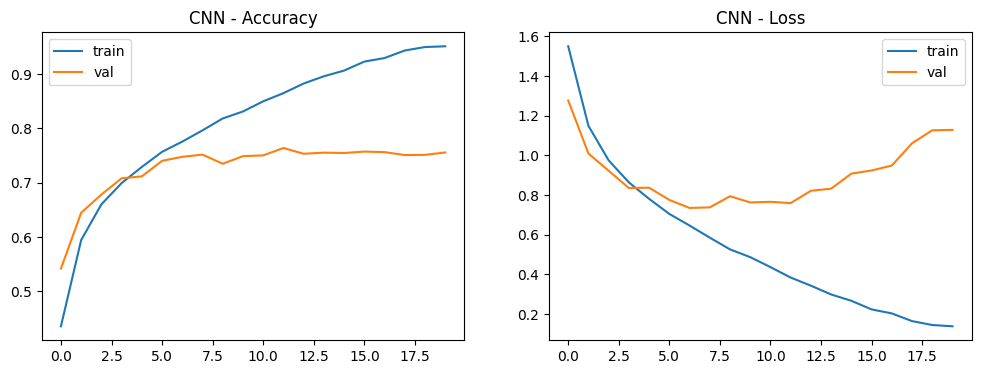

<Figure size 640x480 with 0 Axes>

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step


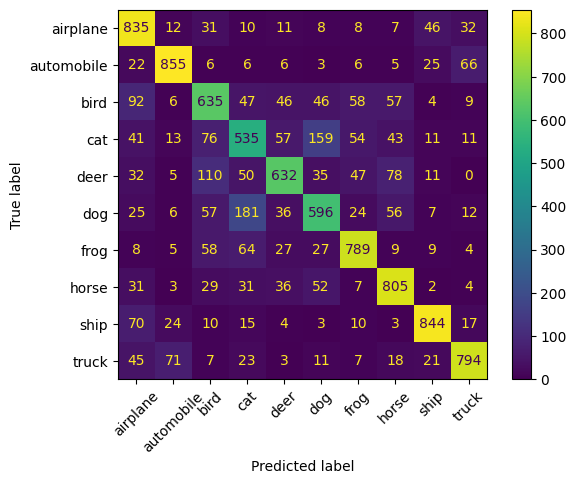

In [8]:
cnn_loss, cnn_acc = cnn.evaluate(x_test, y_test, verbose=0)
print(f"CNN test accuracy: {cnn_acc:.4f}")

plot_history(history_cnn, 'CNN')
plt.savefig('cnn_history.png', dpi=150, bbox_inches='tight')
plt.show()

y_pred_cnn = np.argmax(cnn.predict(x_test), axis=1)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_cnn),
                       display_labels=class_names).plot(xticks_rotation=45)
plt.savefig('cnn_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
print(f"{'Model':<6} {'Test acc':<10} {'Params':<12} {'Time (s)'}")
print(f"{'MLP':<6} {test_acc*100:<10.2f} {mlp.count_params():<12,} {mlp_time:.1f}")
print(f"{'CNN':<6} {cnn_acc*100:<10.2f} {cnn.count_params():<12,} {cnn_time:.1f}")

Model  Test acc   Params       Time (s)
MLP    51.48      1,707,274    31.5
CNN    73.20      356,810      68.5
